In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('output_data/trinuc_constraint.csv')

stats = df.groupby(['Region'])['Constraint'].agg(['mean', 'sem']).unstack()
stats.to_csv('output_data/trinuc_constraint_mean_sem.csv')
stats

      Region        
mean  cds               0.578542
      distalIG         -0.006518
      introns3UTR       0.386683
      introns5UTR       0.376660
      intronsAR         0.152183
      introns_nonUTR    0.248554
      proximal3IG       0.151657
      proximal5IG       0.138679
sem   cds                    NaN
      distalIG               NaN
      introns3UTR            NaN
      introns5UTR            NaN
      intronsAR              NaN
      introns_nonUTR         NaN
      proximal3IG            NaN
      proximal5IG            NaN
dtype: float64

In [3]:
df = pd.read_csv('output_data/singlent_constraint.csv')

stats = df.groupby(['Region'])['Constraint'].agg(['mean', 'sem']).unstack()
stats.to_csv('output_data/singlent_constraint_mean_sem.csv')
stats

      Region        
mean  cds               0.503184
      distalIG         -0.010831
      introns3UTR       0.236375
      introns5UTR       0.289874
      intronsAR         0.140400
      introns_nonUTR    0.246306
      proximal3IG       0.125979
      proximal5IG       0.114880
sem   cds                    NaN
      distalIG               NaN
      introns3UTR            NaN
      introns5UTR            NaN
      intronsAR              NaN
      introns_nonUTR         NaN
      proximal3IG            NaN
      proximal5IG            NaN
dtype: float64

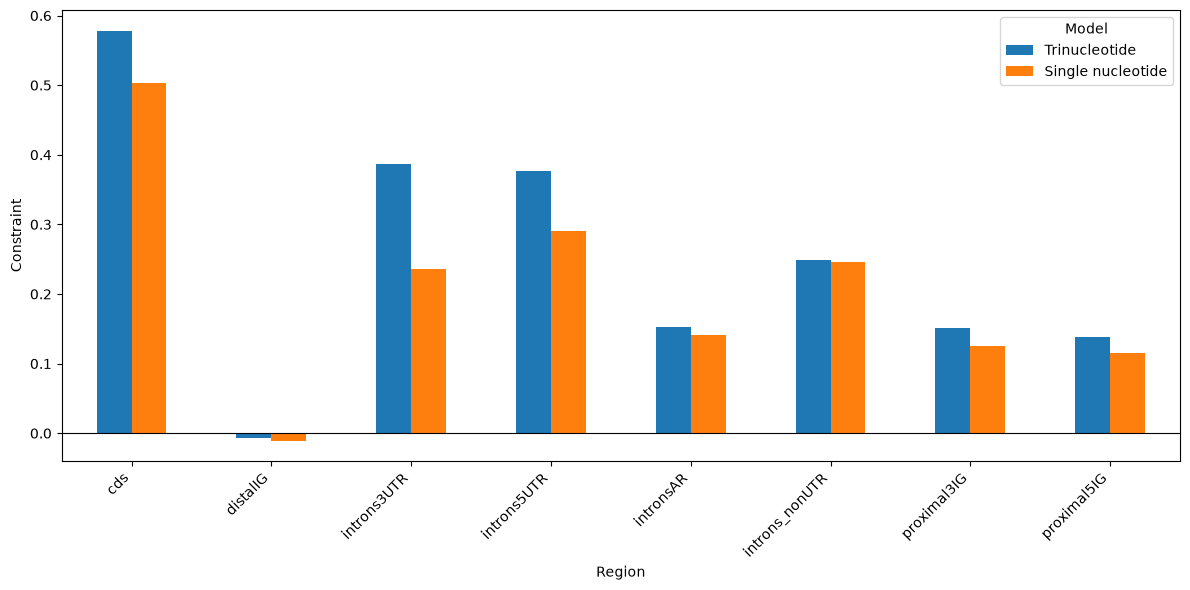

In [4]:
def region_mean_sem(path):
    df = pd.read_csv(path)
    return df.groupby('Region')['Constraint'].agg(['mean', 'sem'])

trinuc = region_mean_sem('output_data/trinuc_constraint.csv')
singlent = region_mean_sem('output_data/singlent_constraint.csv')

mean_df = pd.DataFrame({'Trinucleotide': trinuc['mean'], 'Single nucleotide': singlent['mean']})

ax = mean_df.plot(
    kind='bar',
    capsize=4,
    color=['#1f77b4', '#ff7f0e'],
    figsize=(12, 6)
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Constraint')
ax.set_xlabel('Region')
ax.legend(title='Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()